# 01 · RescueNet — Data Exploration & Preprocessing

**Goal:** understand the dataset (counts, dimensions, class balance, appearance) and produce a model-ready, **resized** copy of the data for notebook 02.

**Why the data is reduced here (once, offline):**

| Problem with training straight on the originals | Effect |
|---|---|
| Every image is 4000×3000 (12 MP JPEG + 12 MP PNG mask) | Decoding dominates each step → GPU sits idle waiting for the DataLoader |
| Old pipeline: train = random 512 crop at full res, val = whole image squashed to 512×512 | Model is validated at a ~7.8× different scale and a distorted aspect ratio from what it trained on → misleading val scores |
| 512 crop of a 4000×3000 image covers ~2 % of the scene | Very little context per sample (a whole building often doesn't fit) |

**Fix:** resize every pair once to **1024×768** (keeps 4:3, both sides divisible by 32). Images use `INTER_AREA`, masks use `INTER_NEAREST` (never interpolate labels). Training then takes 512 crops of the 1024×768 images and validation/test use the full 1024×768 image — **same scale in both**.

**Outputs (in `/kaggle/working`)**: `rescuenet_resized.tar` (resized images + masks), `manifest.csv`, `dataset_info.json`, `class_weights.npz`, `figures/`.
Everything is packed into one tar because Kaggle refuses to save notebook outputs with more than 500 files.

In [1]:
import os, json, random, tarfile, shutil, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
cv2.setNumThreads(0)
Image.MAX_IMAGE_PIXELS = None
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
N_JOBS = os.cpu_count() or 2

def find_data_root(base="/kaggle/input"):
    for p in Path(base).rglob("train-org-img"):
        return p.parent.parent
    raise FileNotFoundError("No 'train-org-img' folder under /kaggle/input - attach the RescueNet dataset.")

DATA_ROOT = find_data_root()
WORK_DIR  = Path("/kaggle/working")
FIG_DIR   = WORK_DIR / "figures"
STAGE_DIR = Path("/tmp/rescuenet_resized")      # staged outside /kaggle/working, then tarred
TAR_PATH  = WORK_DIR / "rescuenet_resized.tar"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET_W, TARGET_H = 1024, 768      # 4:3, divisible by 32
JPEG_QUALITY = 95
SPLITS = ["train", "val", "test"]

# Class IDs as given in the dataset's version note (IDs 0-11 -> 12 classes)
CLASSES = ["Background", "Debris", "Water", "Building_No_Damage", "Building_Minor_Damage",
           "Building_Major_Damage", "Building_Total_Destruction", "Vehicle", "Road", "Tree",
           "Pool", "Sand"]
NUM_CLASSES = len(CLASSES)
PALETTE = np.array([
    [0, 0, 0], [139, 87, 42], [30, 144, 255], [0, 200, 0], [255, 255, 0], [255, 140, 0],
    [220, 20, 60], [255, 0, 255], [128, 128, 128], [0, 100, 0], [0, 255, 255], [238, 214, 175]],
    dtype=np.uint8)

def colorize(mask):
    return PALETTE[np.clip(mask, 0, NUM_CLASSES - 1)]

def legend_handles():
    return [mpatches.Patch(color=PALETTE[i] / 255, label=f"{i}: {c}") for i, c in enumerate(CLASSES)]

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=120, bbox_inches="tight")
    plt.show()

print("DATA_ROOT :", DATA_ROOT)
print("CPU cores :", N_JOBS)

DATA_ROOT : /kaggle/input/datasets/yaroslavchyrko/rescuenet/RescueNet
CPU cores : 4


## 1. Pair images with masks and count per split
Pairs are matched **by file stem** (`xxx.jpg` ↔ `xxx_lab.png`), not by sorted position, so a missing file can never shift every later pair.

split,train,val,test
pairs,3595,449,450


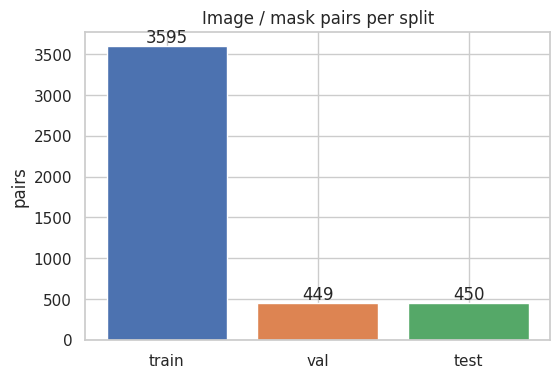

In [2]:
def build_manifest(split):
    img_dir = DATA_ROOT / split / f"{split}-org-img"
    lab_dir = DATA_ROOT / split / f"{split}-label-img"
    imgs  = {p.stem: p for p in img_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
    masks = {p.stem.replace("_lab", ""): p for p in lab_dir.iterdir() if p.suffix.lower() == ".png"}
    ids = sorted(imgs.keys() & masks.keys())
    no_mask, no_img = sorted(imgs.keys() - masks.keys()), sorted(masks.keys() - imgs.keys())
    if no_mask or no_img:
        print(f"[{split}] images without mask: {len(no_mask)} | masks without image: {len(no_img)}")
    return pd.DataFrame({
        "split": split, "id": ids,
        "orig_image": [str(imgs[i].relative_to(DATA_ROOT)) for i in ids],
        "orig_mask":  [str(masks[i].relative_to(DATA_ROOT)) for i in ids],
    })

df = pd.concat([build_manifest(s) for s in SPLITS], ignore_index=True)
split_counts = df["split"].value_counts().reindex(SPLITS)
display(split_counts.to_frame("pairs").T)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(SPLITS, split_counts.values, color=["#4C72B0", "#DD8452", "#55A868"])
ax.bar_label(bars)
ax.set_title("Image / mask pairs per split"); ax.set_ylabel("pairs")
save(fig, "01_split_counts.png")

## 2. Image & mask dimensions (all files)
Only the file headers are read, so this is fast even for every image.

Image sizes (W x H):


count
split img_w img_h       
test  4000  3000     419
      4056  3040      31
train 4000  3000    3449
      4056  3040     146
val   4000  3000     428
      4056  3040      21

Image modes: {'RGB': 4494} | Mask modes: {'L': 4494}
Image/mask size mismatches: 0
Portrait images: 0
Avg image 12.0 MP, 5.25 MB on disk; total dataset on disk 23.73 GB


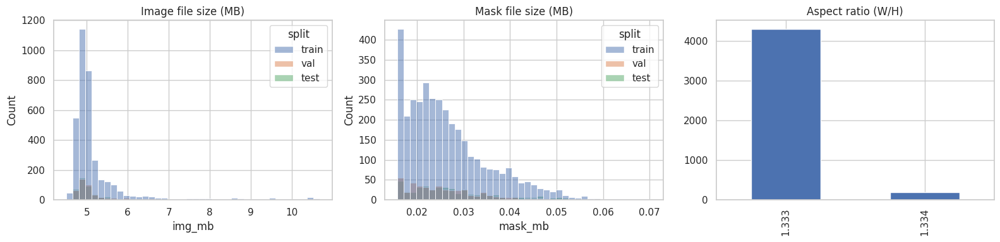

In [3]:
def read_meta(img_rel, mask_rel):
    ip, mp = DATA_ROOT / img_rel, DATA_ROOT / mask_rel
    with Image.open(ip) as im:
        iw, ih, imode = *im.size, im.mode
    with Image.open(mp) as m:
        mw, mh, mmode = *m.size, m.mode
    return iw, ih, imode, mw, mh, mmode, os.path.getsize(ip) / 1e6, os.path.getsize(mp) / 1e6

meta = Parallel(n_jobs=N_JOBS)(delayed(read_meta)(a, b) for a, b in
                               tqdm(zip(df.orig_image, df.orig_mask), total=len(df), desc="headers"))
meta_cols = ["img_w", "img_h", "img_mode", "mask_w", "mask_h", "mask_mode", "img_mb", "mask_mb"]
df[meta_cols] = pd.DataFrame(meta, index=df.index)

print("Image sizes (W x H):")
display(df.groupby(["split", "img_w", "img_h"]).size().rename("count").to_frame())
print("Image modes:", df.img_mode.value_counts().to_dict(), "| Mask modes:", df.mask_mode.value_counts().to_dict())
size_mismatch = df[(df.img_w != df.mask_w) | (df.img_h != df.mask_h)]
print("Image/mask size mismatches:", len(size_mismatch))
print("Portrait images:", int((df.img_h > df.img_w).sum()))
print(f"Avg image {df.img_w.mean() * df.img_h.mean() / 1e6:.1f} MP, {df.img_mb.mean():.2f} MB on disk; "
      f"total dataset on disk {(df.img_mb.sum() + df.mask_mb.sum()) / 1e3:.2f} GB")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x="img_mb", hue="split", bins=40, ax=axes[0]); axes[0].set_title("Image file size (MB)")
sns.histplot(data=df, x="mask_mb", hue="split", bins=40, ax=axes[1]); axes[1].set_title("Mask file size (MB)")
(df.img_w / df.img_h).round(3).value_counts().plot.bar(ax=axes[2]); axes[2].set_title("Aspect ratio (W/H)")
plt.tight_layout(); save(fig, "02_dimensions_filesizes.png")

## 3. What the data looks like

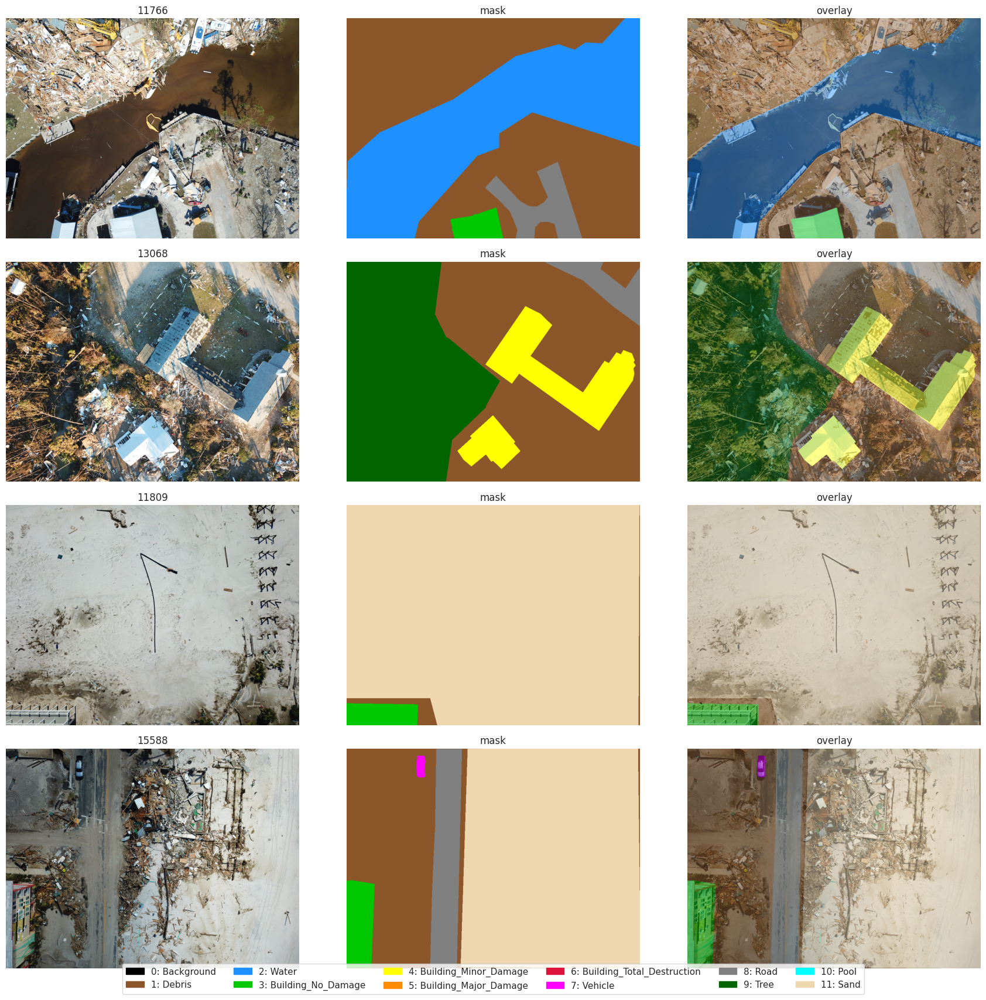

In [4]:
def load_pair(row, scale_w=1000):
    img = cv2.cvtColor(cv2.imread(str(DATA_ROOT / row.orig_image)), cv2.COLOR_BGR2RGB)
    m = cv2.imread(str(DATA_ROOT / row.orig_mask), cv2.IMREAD_UNCHANGED)
    h = int(img.shape[0] * scale_w / img.shape[1])
    return (cv2.resize(img, (scale_w, h), interpolation=cv2.INTER_AREA),
            cv2.resize(m, (scale_w, h), interpolation=cv2.INTER_NEAREST))

samples = df[df.split == "train"].sample(4, random_state=SEED)
fig, axes = plt.subplots(len(samples), 3, figsize=(18, 4.2 * len(samples)))
for r, row in enumerate(samples.itertuples()):
    img, m = load_pair(row)
    overlay = (0.55 * img + 0.45 * colorize(m)).astype(np.uint8)
    for c, (im, t) in enumerate([(img, f"{row.id}"), (colorize(m), "mask"), (overlay, "overlay")]):
        axes[r, c].imshow(im); axes[r, c].set_title(t); axes[r, c].axis("off")
fig.legend(handles=legend_handles(), loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(); save(fig, "03_samples.png")

## 4. Class distribution (every mask, full resolution)
Pixel share per class, share of images containing each class, and which classes appear together. Also checks for label values outside 0–11.

Max label value found: 11 | pixels with label >= 12: 0


split,train,val,test
cls,,,
Background,5.233000,4.999000,5.235000
Debris,29.702000,28.299000,30.870000
Water,8.127000,8.679000,7.038000
Building_No_Damage,2.648000,2.440000,2.863000
Building_Minor_Damage,2.632000,2.443000,2.648000
Building_Major_Damage,1.682000,1.674000,1.346000
Building_Total_Destruction,1.442000,1.242000,1.450000
Vehicle,0.331000,0.359000,0.313000
Road,8.516000,8.488000,8.770000


Train imbalance: most frequent / least frequent class = 523x


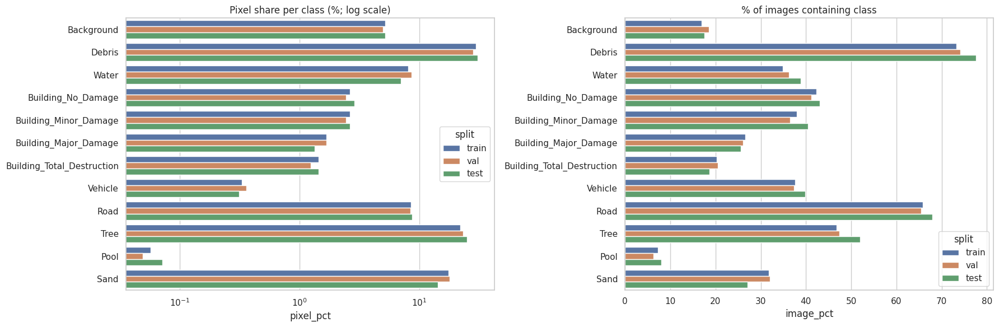

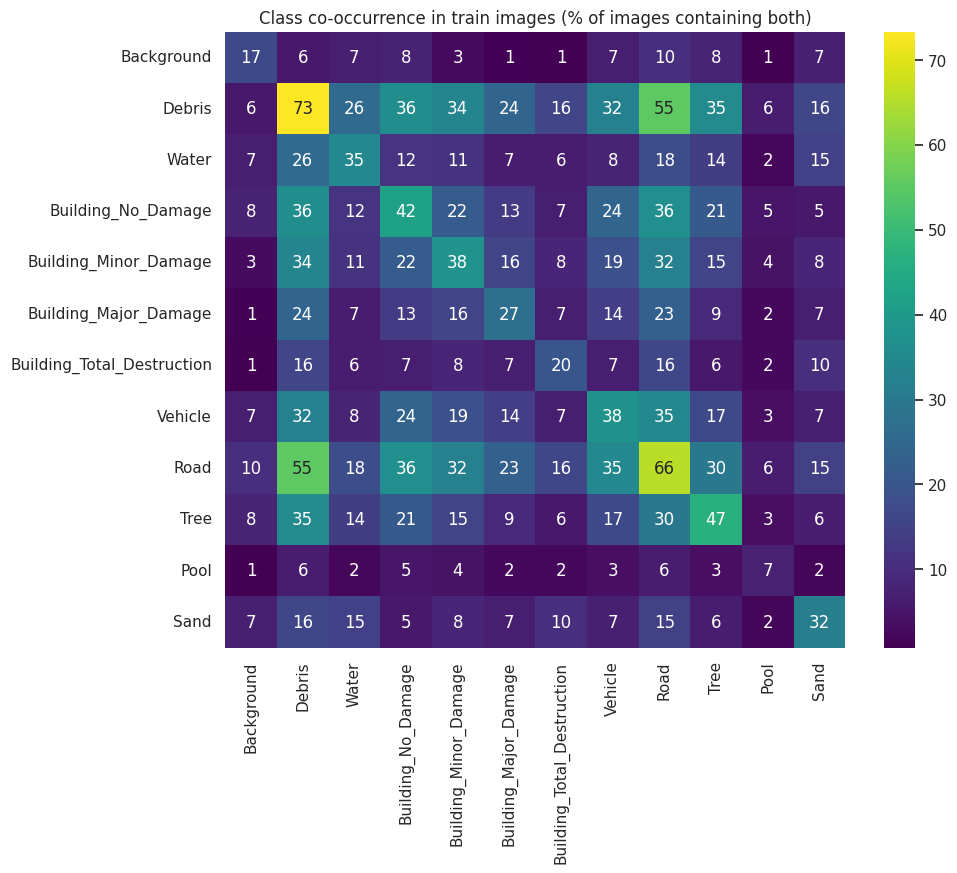

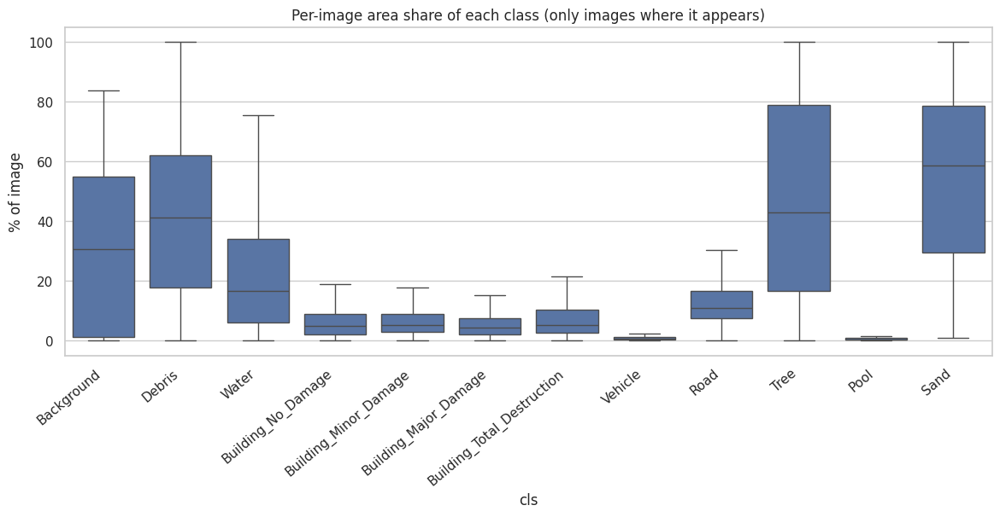

In [5]:
def mask_hist(mask_rel):
    m = cv2.imread(str(DATA_ROOT / mask_rel), cv2.IMREAD_UNCHANGED)
    if m.ndim == 3:
        m = m[..., 0]
    h = np.bincount(m.ravel(), minlength=256)
    return h[:256] if h.size >= 256 else h, int(m.max())

res = Parallel(n_jobs=N_JOBS)(delayed(mask_hist)(p) for p in tqdm(df.orig_mask, desc="masks"))
orig_counts = np.stack([r[0][:256] for r in res]).astype(np.int64)
max_label = max(r[1] for r in res)

unexpected = orig_counts[:, NUM_CLASSES:].sum()
print(f"Max label value found: {max_label} | pixels with label >= {NUM_CLASSES}: {unexpected}")
assert unexpected == 0 and max_label < NUM_CLASSES, "Masks contain labels outside the class list - fix CLASSES first."
orig_counts = orig_counts[:, :NUM_CLASSES]

rows = []
for s in SPLITS:
    sel = (df.split == s).values
    pix = orig_counts[sel].sum(0)
    pres = (orig_counts[sel] > 0).mean(0) * 100
    for i, c in enumerate(CLASSES):
        rows.append(dict(split=s, cls=c, pixels=pix[i], pixel_pct=pix[i] / pix.sum() * 100, image_pct=pres[i]))
dist = pd.DataFrame(rows)
display(dist.pivot(index="cls", columns="split", values="pixel_pct").loc[CLASSES][SPLITS].round(3)
        .style.background_gradient(cmap="Blues").set_caption("Pixel share (%)"))

tr = dist[dist.split == "train"].set_index("cls").loc[CLASSES]
nz = tr.pixels[tr.pixels > 0]
print(f"Train imbalance: most frequent / least frequent class = {nz.max() / nz.min():,.0f}x")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(data=dist, y="cls", x="pixel_pct", hue="split", ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_title("Pixel share per class (%; log scale)"); axes[0].set_ylabel("")
sns.barplot(data=dist, y="cls", x="image_pct", hue="split", ax=axes[1])
axes[1].set_title("% of images containing class"); axes[1].set_ylabel("")
plt.tight_layout(); save(fig, "04_class_distribution.png")

pres_tr = (orig_counts[(df.split == "train").values] > 0).astype(np.float64)
co = pres_tr.T @ pres_tr / len(pres_tr) * 100
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(co, annot=True, fmt=".0f", cmap="viridis", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_title("Class co-occurrence in train images (% of images containing both)")
save(fig, "05_cooccurrence.png")

frac = orig_counts[(df.split == "train").values] / orig_counts[(df.split == "train").values].sum(1, keepdims=True) * 100
frac_df = pd.DataFrame(frac, columns=CLASSES).melt(var_name="cls", value_name="pct")
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=frac_df[frac_df.pct > 0], x="cls", y="pct", ax=ax, showfliers=False)
ax.set_title("Per-image area share of each class (only images where it appears)"); ax.set_ylabel("% of image")
plt.xticks(rotation=40, ha="right"); save(fig, "06_per_image_area.png")

## 5. Colour statistics

Per-image mean (avg): [0.5316 0.5208 0.48  ] | per-image std (avg): [0.2416 0.2349 0.2328]


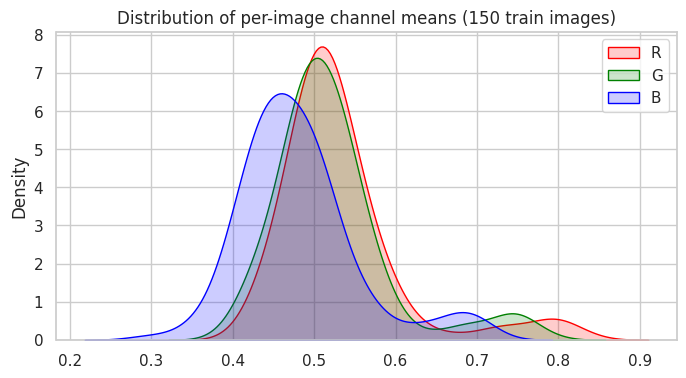

In [6]:
def rgb_stats(img_rel):
    img = cv2.imread(str(DATA_ROOT / img_rel))
    img = cv2.resize(img, (TARGET_W, TARGET_H), interpolation=cv2.INTER_AREA)[..., ::-1] / 255.0
    return img.reshape(-1, 3).mean(0), img.reshape(-1, 3).std(0)

train_paths = df[df.split == "train"].orig_image
sample_paths = train_paths.sample(min(150, len(train_paths)), random_state=SEED)
st = Parallel(n_jobs=N_JOBS)(delayed(rgb_stats)(p) for p in tqdm(sample_paths, desc="rgb"))
means = np.stack([s[0] for s in st]); stds = np.stack([s[1] for s in st])
print("Per-image mean (avg):", means.mean(0).round(4), "| per-image std (avg):", stds.mean(0).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
for i, (c, col) in enumerate(zip("RGB", ["red", "green", "blue"])):
    sns.kdeplot(means[:, i], color=col, label=c, ax=ax, fill=True, alpha=.2)
ax.set_title(f"Distribution of per-image channel means ({len(sample_paths)} train images)"); ax.legend()
save(fig, "07_rgb_means.png")

## 6. Why the old crop / resize setup was a problem
Left two panels = what the previous pipeline fed the model in training vs validation. Right = the new setup.

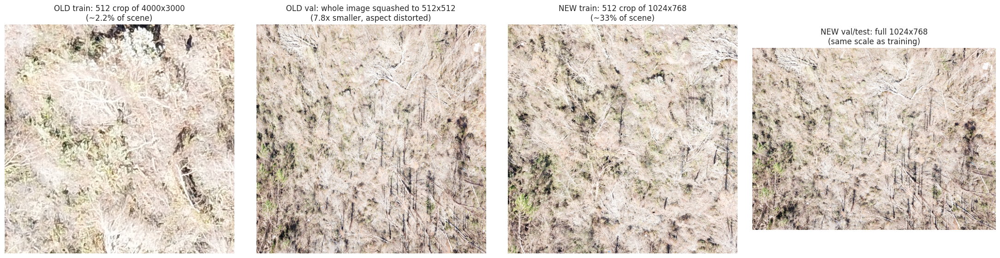

In [7]:
row = df[df.split == "train"].sample(1, random_state=1).iloc[0]
full = cv2.cvtColor(cv2.imread(str(DATA_ROOT / row.orig_image)), cv2.COLOR_BGR2RGB)
H, W = full.shape[:2]
y, x = np.random.randint(0, H - 512), np.random.randint(0, W - 512)
old_train = full[y:y + 512, x:x + 512]
old_val = cv2.resize(full, (512, 512), interpolation=cv2.INTER_AREA)
new_img = cv2.resize(full, (TARGET_W, TARGET_H), interpolation=cv2.INTER_AREA)
ny, nx = np.random.randint(0, TARGET_H - 512), np.random.randint(0, TARGET_W - 512)
new_train = new_img[ny:ny + 512, nx:nx + 512]

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, im, t in zip(axes, [old_train, old_val, new_train, new_img],
                     [f"OLD train: 512 crop of {W}x{H}\n(~{512 * 512 / (W * H) * 100:.1f}% of scene)",
                      "OLD val: whole image squashed to 512x512\n(7.8x smaller, aspect distorted)",
                      f"NEW train: 512 crop of {TARGET_W}x{TARGET_H}\n(~{512 * 512 / (TARGET_W * TARGET_H) * 100:.0f}% of scene)",
                      f"NEW val/test: full {TARGET_W}x{TARGET_H}\n(same scale as training)"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.tight_layout(); save(fig, "08_scale_comparison.png")

## 7. Preprocess: resize every pair once to 1024×768
Masks use nearest-neighbour so no new/invalid labels are created. Class counts and RGB sums are gathered in the same pass.

Resized 4494 pairs in 561s
Train mean (RGB): [0.5258 0.5168 0.4771] | std: [0.2556 0.2474 0.2467]


,original_%,resized_%,diff_pp
Background,5.2332,5.2348,0.0016
Debris,29.7020,29.7071,0.0050
Water,8.1268,8.1336,0.0068
Building_No_Damage,2.6477,2.6505,0.0028
Building_Minor_Damage,2.6318,2.6336,0.0018
Building_Major_Damage,1.6817,1.6825,0.0008
Building_Total_Destruction,1.4419,1.4429,0.0010
Vehicle,0.3314,0.3317,0.0003
Road,8.5161,8.5116,-0.0045
Tree,22.0517,22.0195,-0.0322


Max absolute change: 0.0322 percentage points
Images containing each class (original -> resized):
  Background                     769 ->   765
  Debris                        3318 ->  3307
  Water                         1592 ->  1591
  Building_No_Damage            1902 ->  1902
  Building_Minor_Damage         1711 ->  1711
  Building_Major_Damage         1188 ->  1188
  Building_Total_Destruction     905 ->   905
  Vehicle                       1701 ->  1701
  Road                          2965 ->  2965
  Tree                          2129 ->  2129
  Pool                           327 ->   327
  Sand                          1409 ->  1409


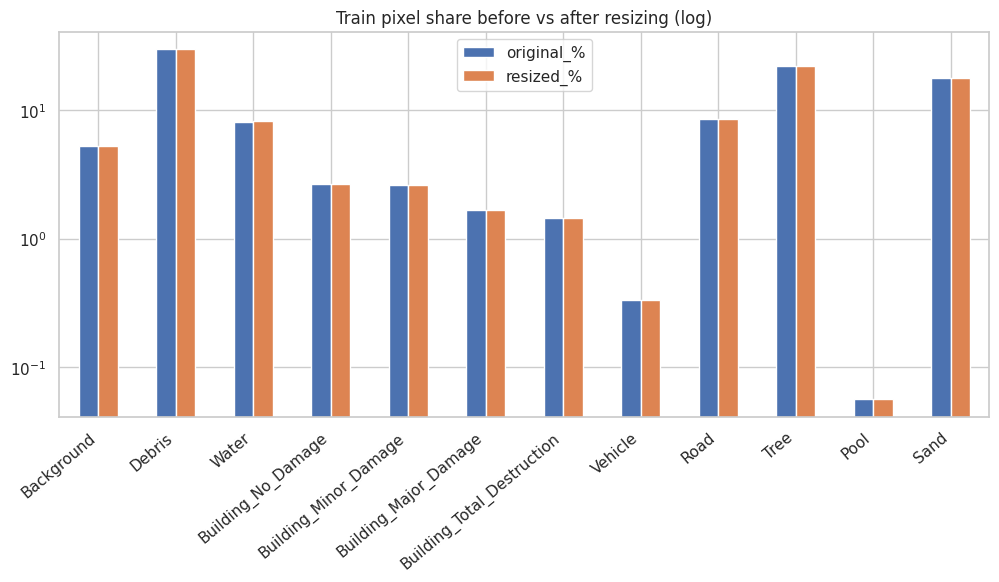

In [8]:
if STAGE_DIR.exists():
    shutil.rmtree(STAGE_DIR)
for s in SPLITS:
    (STAGE_DIR / s / "images").mkdir(parents=True, exist_ok=True)
    (STAGE_DIR / s / "masks").mkdir(parents=True, exist_ok=True)

def resize_pair(split, sid, img_rel, mask_rel):
    img = cv2.imread(str(DATA_ROOT / img_rel), cv2.IMREAD_COLOR)
    m = cv2.imread(str(DATA_ROOT / mask_rel), cv2.IMREAD_UNCHANGED)
    if m.ndim == 3:
        m = m[..., 0]
    img_r = cv2.resize(img, (TARGET_W, TARGET_H), interpolation=cv2.INTER_AREA)
    m_r = cv2.resize(m.astype(np.uint8), (TARGET_W, TARGET_H), interpolation=cv2.INTER_NEAREST)
    cv2.imwrite(str(STAGE_DIR / split / "images" / f"{sid}.jpg"), img_r, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
    cv2.imwrite(str(STAGE_DIR / split / "masks" / f"{sid}.png"), m_r)
    rgb = img_r[..., ::-1].reshape(-1, 3).astype(np.float64) / 255.0
    return np.bincount(m_r.ravel(), minlength=NUM_CLASSES)[:NUM_CLASSES], rgb.sum(0), (rgb ** 2).sum(0)

t0 = time.time()
out = Parallel(n_jobs=N_JOBS)(delayed(resize_pair)(*a) for a in
                              tqdm(zip(df.split, df.id, df.orig_image, df.orig_mask), total=len(df), desc="resize"))
print(f"Resized {len(df)} pairs in {time.time() - t0:.0f}s")

resized_counts = np.stack([o[0] for o in out]).astype(np.int64)
df["image"] = df.split + "/images/" + df.id + ".jpg"
df["mask"] = df.split + "/masks/" + df.id + ".png"

tr_sel = (df.split == "train").values
n_pix = tr_sel.sum() * TARGET_W * TARGET_H
s1 = np.stack([o[1] for o, t in zip(out, tr_sel) if t]).sum(0)
s2 = np.stack([o[2] for o, t in zip(out, tr_sel) if t]).sum(0)
DATA_MEAN = s1 / n_pix
DATA_STD = np.sqrt(s2 / n_pix - DATA_MEAN ** 2)
print("Train mean (RGB):", DATA_MEAN.round(4), "| std:", DATA_STD.round(4))

# Did resizing preserve the class balance?
o = orig_counts[tr_sel].sum(0); o = o / o.sum() * 100
r = resized_counts[tr_sel].sum(0); r = r / r.sum() * 100
cmp = pd.DataFrame({"original_%": o, "resized_%": r, "diff_pp": r - o}, index=CLASSES)
display(cmp.round(4))
print("Max absolute change:", np.abs(r - o).max().round(4), "percentage points")
lost = [(CLASSES[c], int((orig_counts[:, c] > 0).sum()), int((resized_counts[:, c] > 0).sum())) for c in range(NUM_CLASSES)]
print("Images containing each class (original -> resized):")
for n, a, b in lost:
    print(f"  {n:28s} {a:5d} -> {b:5d}")

fig, ax = plt.subplots(figsize=(12, 5))
cmp[["original_%", "resized_%"]].plot.bar(ax=ax, logy=True)
ax.set_title("Train pixel share before vs after resizing (log)"); plt.xticks(rotation=40, ha="right")
save(fig, "09_resize_class_preservation.png")

## 8. Class weights (from the resized train masks)
Median-frequency balancing, clipped at 10 so the rarest classes don't dominate the loss. An inverse-sqrt variant is also saved as a gentler option.

,pixel_freq_%,median,median_clipped,inv_sqrt
Background,5.2348,0.7532,0.7532,0.4981
Debris,29.7071,0.1327,0.1327,0.2091
Water,8.1336,0.4847,0.4847,0.3996
Building_No_Damage,2.6505,1.4875,1.4875,0.6999
Building_Minor_Damage,2.6336,1.4971,1.4971,0.7022
Building_Major_Damage,1.6825,2.3433,2.3433,0.8785
Building_Total_Destruction,1.4429,2.7325,2.7325,0.9487
Vehicle,0.3317,11.8868,10.0000,1.9786
Road,8.5116,0.4632,0.4632,0.3906
Tree,22.0195,0.1791,0.1791,0.2428


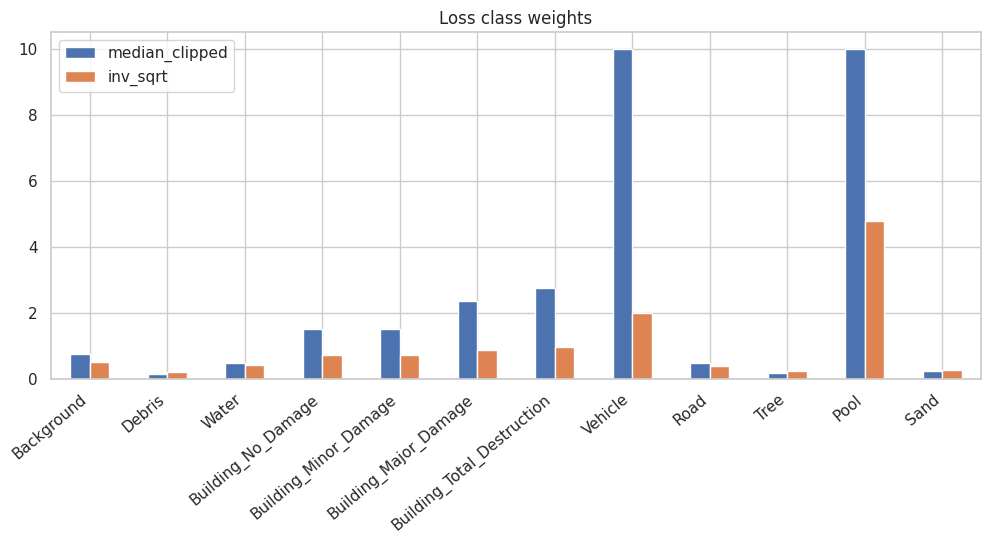

In [9]:
train_counts = resized_counts[tr_sel].sum(0).astype(np.float64)
freq = train_counts / train_counts.sum()
present = train_counts > 0
if (~present).any():
    print("WARNING - classes absent from train:", [CLASSES[i] for i in np.where(~present)[0]])
safe = np.maximum(freq, 1e-12)
w_median = np.where(present, np.median(freq[present]) / safe, 0.0)
w_median_clipped = np.clip(w_median, 0, 10.0)
w_inv_sqrt = np.where(present, 1 / np.sqrt(safe), 0.0)
w_inv_sqrt = w_inv_sqrt / w_inv_sqrt[present].mean()

wdf = pd.DataFrame({"pixel_freq_%": freq * 100, "median": w_median,
                    "median_clipped": w_median_clipped, "inv_sqrt": w_inv_sqrt}, index=CLASSES)
display(wdf.round(4))
fig, ax = plt.subplots(figsize=(12, 4.5))
wdf[["median_clipped", "inv_sqrt"]].plot.bar(ax=ax); ax.set_title("Loss class weights"); plt.xticks(rotation=40, ha="right")
save(fig, "10_class_weights.png")

## 9. Sanity check on the resized files

test  15639: image (768, 1024, 3) uint8 | mask (768, 1024) uint8 labels [1, 4, 5, 7, 8, 11]
train 16228: image (768, 1024, 3) uint8 | mask (768, 1024) uint8 labels [0, 3, 4, 5, 7, 8, 9]
val   16232: image (768, 1024, 3) uint8 | mask (768, 1024) uint8 labels [1, 3, 4, 7, 8, 9]


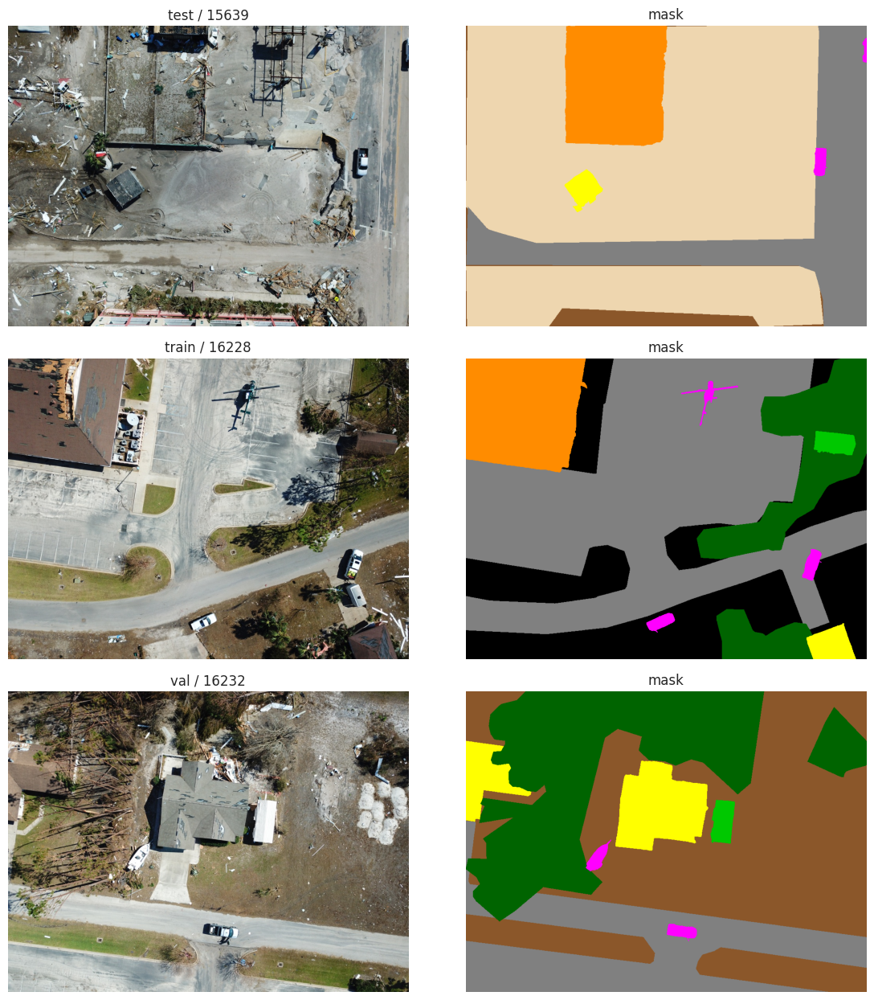

In [10]:
chk = df.groupby("split").sample(1, random_state=SEED)
fig, axes = plt.subplots(len(chk), 2, figsize=(12, 4.2 * len(chk)))
for i, row in enumerate(chk.itertuples()):
    img = cv2.cvtColor(cv2.imread(str(STAGE_DIR / row.image)), cv2.COLOR_BGR2RGB)
    m = cv2.imread(str(STAGE_DIR / row.mask), cv2.IMREAD_UNCHANGED)
    assert img.shape[:2] == (TARGET_H, TARGET_W) and m.shape == (TARGET_H, TARGET_W), "bad shape"
    assert m.dtype == np.uint8 and m.max() < NUM_CLASSES, "bad mask values"
    print(f"{row.split:5s} {row.id}: image {img.shape} {img.dtype} | mask {m.shape} {m.dtype} labels {np.unique(m).tolist()}")
    axes[i, 0].imshow(img); axes[i, 0].set_title(f"{row.split} / {row.id}"); axes[i, 0].axis("off")
    axes[i, 1].imshow(colorize(m)); axes[i, 1].set_title("mask"); axes[i, 1].axis("off")
plt.tight_layout(); save(fig, "11_resized_check.png")

## 10. Save everything for notebook 02

In [11]:
df[["split", "id", "image", "mask", "orig_image", "orig_mask", "img_w", "img_h"]].to_csv(WORK_DIR / "manifest.csv", index=False)
np.savez(WORK_DIR / "class_weights.npz", median=w_median, median_clipped=w_median_clipped, inv_sqrt=w_inv_sqrt)

info = {
    "classes": CLASSES,
    "num_classes": NUM_CLASSES,
    "palette": PALETTE.tolist(),
    "image_size_wh": [TARGET_W, TARGET_H],
    "original_size_wh": [int(df.img_w.mode()[0]), int(df.img_h.mode()[0])],
    "data_mean": DATA_MEAN.tolist(), "data_std": DATA_STD.tolist(),
    "imagenet_mean": [0.485, 0.456, 0.406], "imagenet_std": [0.229, 0.224, 0.225],
    "class_weights": {"median": w_median.tolist(), "median_clipped": w_median_clipped.tolist(),
                      "inv_sqrt": w_inv_sqrt.tolist()},
    "train_pixel_counts": train_counts.astype(int).tolist(),
    "split_sizes": split_counts.to_dict(),
    "tar_name": TAR_PATH.name, "tar_root": "rescuenet_resized",
}
with open(WORK_DIR / "dataset_info.json", "w") as f:
    json.dump(info, f, indent=2)

t0 = time.time()
with tarfile.open(TAR_PATH, "w") as tar:          # JPEG/PNG are already compressed -> plain tar
    tar.add(STAGE_DIR, arcname="rescuenet_resized")
print(f"Tar written in {time.time() - t0:.0f}s: {TAR_PATH.stat().st_size / 1e9:.2f} GB")

files = [p for p in WORK_DIR.rglob("*") if p.is_file()]
print(f"\n{len(files)} output files (Kaggle limit is 500):")
for p in sorted(files):
    print(f"  {p.relative_to(WORK_DIR)}  ({p.stat().st_size / 1e6:.2f} MB)")

Tar written in 3s: 2.13 GB

16 output files (Kaggle limit is 500):
  __notebook__.ipynb  (10.16 MB)
  class_weights.npz  (0.00 MB)
  dataset_info.json  (0.00 MB)
  figures/01_split_counts.png  (0.02 MB)
  figures/02_dimensions_filesizes.png  (0.05 MB)
  figures/03_samples.png  (4.70 MB)
  figures/04_class_distribution.png  (0.07 MB)
  figures/05_cooccurrence.png  (0.14 MB)
  figures/06_per_image_area.png  (0.08 MB)
  figures/07_rgb_means.png  (0.05 MB)
  figures/08_scale_comparison.png  (3.32 MB)
  figures/09_resize_class_preservation.png  (0.07 MB)
  figures/10_class_weights.png  (0.07 MB)
  figures/11_resized_check.png  (1.90 MB)
  manifest.csv  (0.59 MB)
  rescuenet_resized.tar  (2127.00 MB)
